# CLIN — data checks before (re)training the diffusion model

**Purpose.** Look at the data the CLIN diffusion model is trained on and conditioned with, and list everything in the data that could make training or reconstruction go wrong. Also includes a section on whether a diffusion model suits a dataset of this size.

**Setup it mirrors** (from `clin_era5_reconstruction.py` in `michaelh00/clin_ubelix_bundle`):

| | |
|---|---|
| Field | de-warmed ERA5 daily 2 m temperature, 128 lat × 192 lon, 0.25°, 34.5–66.25 N × 12.25 W–35.5 E |
| Training | **unconditional** diffusion on complete ERA5 fields, train 1960–2025, val 1950–1959, test 1940–1949 |
| Static conditioning | elevation, land–sea mask, sin/cos of day-of-leap-year |
| Normalisation | one global z-score for temperature (scalar mean/std) |
| Use of stations | only at sampling time, via single-pass replacement inpainting on the station grid cells |
| Historical period | 1667–1939, 634 station grid cells (`hist_obs.nc`) |

**How to read it.** Every check that finds something calls `flag(level, message)`. The last cell prints all flags in one table:
- `ISSUE`: will bias or break training or evaluation if ignored.
- `WARN`: worth a decision.
- `INFO`: a fact to know.

**Runtime and memory.** Loading all 86 ERA5 years as float32 takes about 3 GB of RAM, plus about 2.4 GB for the covariance matrix in §8. Expect roughly 5–10 min, mostly file I/O. Set `CLIN_DATA_DIR` if the data folder isn't next to or one level above this notebook's folder.

In [1]:
import os, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

from clin_common import DATA_DIR   # CLIN_DATA_DIR, or "Final CLIN variables" next to / above this folder
assert DATA_DIR.exists(), DATA_DIR

# Mirror the training config
TRAIN_YEARS, VAL_YEARS, TEST_YEARS = (1960, 2025), (1950, 1959), (1940, 1949)
T0 = pd.Timestamp("1667-01-01")
RNG = np.random.default_rng(0)

# Chart styling: recessive axes, fixed categorical order
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#898781", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.prop_cycle": plt.cycler(color=C), "lines.linewidth": 1.6, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.titlesize": 11, "axes.titleweight": "bold",
})
SPLIT_COLORS = {"test": C[1], "val": C[3], "train": C[0]}

FLAGS = []
def flag(level, msg):
    FLAGS.append((level, msg))
    print(f"[{level}] {msg}")

def shade_splits(ax):
    for name, (a, b) in [("test", TEST_YEARS), ("val", VAL_YEARS)]:
        ax.axvspan(a - 0.5, b + 0.5, color=SPLIT_COLORS[name], alpha=0.12, lw=0)
        ax.text((a + b) / 2, 1.0, name, transform=ax.get_xaxis_transform(), ha="center", va="bottom",
                fontsize=8, color="#52514e")

## 1. File inventory and format checks

These are the issues that already bit the project once: axes transposed, the metadata column order, and the `day_index` convention. The checks re-test them so a re-implementation doesn't repeat them.

In [2]:
def describe(path):
    ds = xr.open_dataset(path, decode_times=False)
    out = {v: (ds[v].dims, ds[v].shape, str(ds[v].dtype)) for v in ds.data_vars}
    ds.close()
    return out

for f in ["ERA5_elevation.nc", "ERA5_lsm.nc", "T_ERA5_1940.nc", "hist_obs.nc"]:
    print(f, describe(DATA_DIR / f))

era5_files = sorted(DATA_DIR.glob("T_ERA5_*.nc"))
years = [int(p.stem.split("_")[-1]) for p in era5_files]
missing = sorted(set(range(1940, 2026)) - set(years))
print(f"{len(era5_files)} ERA5 year files, {years[0]}-{years[-1]}, missing: {missing or 'none'}")
if missing:
    flag("ISSUE", f"Missing ERA5 years: {missing}")

flag("INFO", "netCDF variables are stored as (lon, lat, day_index) / (lon, lat) / (id, day_index): always read by "
             "dimension NAME, never by position. The xlsx summary documents the dims in a different order than the files.")

ERA5_elevation.nc {'elev': (('lon', 'lat'), (192, 128), 'float64')}
ERA5_lsm.nc {'lsm': (('lon', 'lat'), (192, 128), 'float64')}
T_ERA5_1940.nc {'T_ERA5': (('lon', 'lat', 'day_index'), (192, 128, 366), 'float64')}


hist_obs.nc {'hist_obs': (('id', 'day_index'), (634, 99710), 'float64')}
86 ERA5 year files, 1940-2025, missing: none
[INFO] netCDF variables are stored as (lon, lat, day_index) / (lon, lat) / (id, day_index): always read by dimension NAME, never by position. The xlsx summary documents the dims in a different order than the files.


grid 128 x 192 | lat 66.25 -> 34.5 | lon -12.25 -> 35.5
lat step [-0.25] lon step [0.25]
elevation -80..2426 m | lsm 0.00..1.00 | land (lsm>0.5) = 55.3% of cells | fractional lsm cells = 37.4%
UNet friendliness: 128 = 2^7, 192 = 3*2^6 -> at most 6 halvings keep integer sizes
[INFO] 45% of the grid is sea (lsm<0.5) and 37% of cells are fractional coast. Stations sit in land/coastal cells, so sea cells are reconstructed far from any observation. A domain-averaged RMSE mixes both; report land and sea separately.


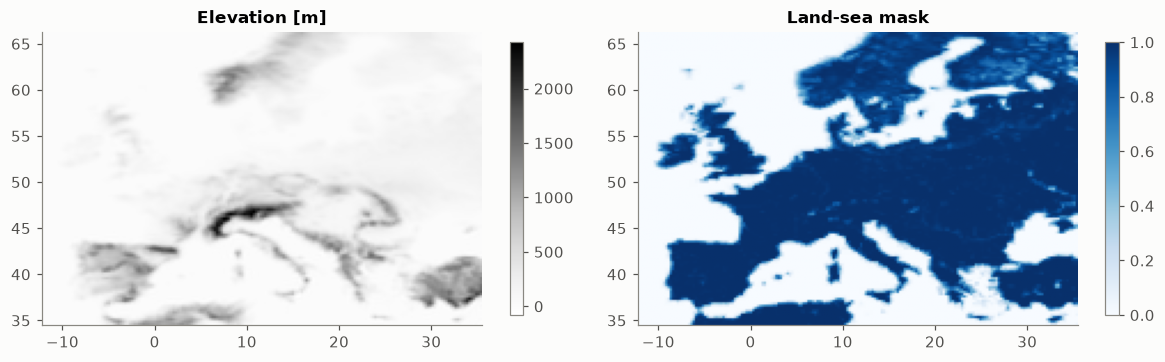

In [3]:
# Static fields and grid
elev_ds = xr.open_dataset(DATA_DIR / "ERA5_elevation.nc")
lsm_ds = xr.open_dataset(DATA_DIR / "ERA5_lsm.nc")
LAT, LON = elev_ds.lat.values, elev_ds.lon.values
ELEV = elev_ds.elev.transpose("lat", "lon").values.astype(np.float32)
LSM = lsm_ds.lsm.transpose("lat", "lon").values.astype(np.float32)
NLAT, NLON = len(LAT), len(LON)
LAND = LSM > 0.5

print("grid", NLAT, "x", NLON, "| lat", LAT[0], "->", LAT[-1], "| lon", LON[0], "->", LON[-1])
print("lat step", np.unique(np.round(np.diff(LAT), 6)), "lon step", np.unique(np.round(np.diff(LON), 6)))
assert np.allclose(lsm_ds.lat, LAT) and np.allclose(lsm_ds.lon, LON)
print(f"elevation {ELEV.min():.0f}..{ELEV.max():.0f} m | lsm {LSM.min():.2f}..{LSM.max():.2f} | "
      f"land (lsm>0.5) = {LAND.mean():.1%} of cells | fractional lsm cells = {((LSM>0.01)&(LSM<0.99)).mean():.1%}")
print("UNet friendliness: 128 = 2^7, 192 = 3*2^6 -> at most 6 halvings keep integer sizes")
flag("INFO", f"{1 - LAND.mean():.0%} of the grid is sea (lsm<0.5) and {((LSM>0.01)&(LSM<0.99)).mean():.0%} of cells are "
             "fractional coast. Stations sit in land/coastal cells, so sea cells are reconstructed far from any observation. "
             "A domain-averaged RMSE mixes both; report land and sea separately.")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
im = ax[0].imshow(ELEV, extent=[LON[0], LON[-1], LAT[-1], LAT[0]], cmap="Greys"); ax[0].set_title("Elevation [m]")
plt.colorbar(im, ax=ax[0], shrink=.8)
im = ax[1].imshow(LSM, extent=[LON[0], LON[-1], LAT[-1], LAT[0]], cmap="Blues"); ax[1].set_title("Land-sea mask")
plt.colorbar(im, ax=ax[1], shrink=.8)
for a in ax: a.grid(False)
plt.tight_layout()

In [4]:
# day_index convention and continuity
expected = 1
day_index_all, grid_ok = [], True
for p, y in zip(era5_files, years):
    ds = xr.open_dataset(p, decode_times=False)
    di = ds.day_index.values.astype(np.int64)
    grid_ok &= np.allclose(ds.lat, LAT) and np.allclose(ds.lon, LON)
    first_expected = (pd.Timestamp(f"{y}-01-01") - T0).days + 1  # 1-based
    ndays = 366 if pd.Timestamp(f"{y}-01-01").is_leap_year else 365
    if di[0] != first_expected or len(di) != ndays or np.any(np.diff(di) != 1):
        flag("ISSUE", f"{p.name}: day_index not contiguous/expected ({di[0]}..{di[-1]}, n={len(di)})")
    day_index_all.append(di)
    ds.close()
day_index_all = np.concatenate(day_index_all)
print("all ERA5 grids identical to static grid:", grid_ok)
print("ERA5 day_index", day_index_all[0], "->", day_index_all[-1], "contiguous:", np.all(np.diff(day_index_all) == 1))

h_ds = xr.open_dataset(DATA_DIR / "hist_obs.nc", decode_times=False)
h_di = h_ds.day_index.values.astype(np.int64)
print("hist_obs day_index", h_di[0], "->", h_di[-1], "contiguous:", np.all(np.diff(h_di) == 1))
print("ERA5 day_index attr:", xr.open_dataset(era5_files[0], decode_times=False).day_index.attrs)
flag("WARN", "day_index is 1-BASED (1 = 1667-01-01) although its attribute says 'days since 1667-01-01' "
             "(which would make it 0-based). A CF-aware reader (xarray decode_times) would shift every date "
             "by +1 day. Always decode as T0 + (day_index - 1).")
flag("INFO", f"hist_obs covers {T0.date()}..{(T0 + pd.Timedelta(days=int(h_di[-1]) - 1)).date()} and ERA5 starts the next "
             "day: there is NO overlap period to compare stations and ERA5 directly.")

all ERA5 grids identical to static grid: True
ERA5 day_index 99711 -> 131122 contiguous: True
hist_obs day_index 1 -> 99710 contiguous: True
ERA5 day_index attr: {'long_name': 'days since 1667-01-01'}
[WARN] day_index is 1-BASED (1 = 1667-01-01) although its attribute says 'days since 1667-01-01' (which would make it 0-based). A CF-aware reader (xarray decode_times) would shift every date by +1 day. Always decode as T0 + (day_index - 1).
[INFO] hist_obs covers 1667-01-01..1939-12-31 and ERA5 starts the next day: there is NO overlap period to compare stations and ERA5 directly.


In [5]:
# sin/cos day-of-year encoding: verify it is the 'day-of-leap-year' scheme used by the code
cos_doy = np.loadtxt(DATA_DIR / "cos_doy_1667_2025.txt")
sin_doy = np.loadtxt(DATA_DIR / "sin_doy_1667_2025.txt")
ALL_DATES = pd.date_range("1667-01-01", "2025-12-31")
print("doy files length", len(cos_doy), "| days 1667-01-01..2025-12-31:", len(ALL_DATES))

def day_of_leap_year(dates):
    d = pd.DatetimeIndex(dates)
    return d.dayofyear + ((~d.is_leap_year) & (d.month >= 3)).astype(int)

DOLY_ALL = np.asarray(day_of_leap_year(ALL_DATES))
pred = np.exp(2j * np.pi * DOLY_ALL / 366)
err_days = np.abs(np.angle((cos_doy + 1j * sin_doy) / pred)) / (2 * np.pi) * 366
print(f"max mismatch vs 2*pi*day_of_leap_year/366: {err_days.max():.2e} days")
if err_days.max() < 1e-3:
    flag("INFO", "sin/cos files = 2*pi*day_of_leap_year/366 (Mar 1 is always day 61, Dec 31 is day 366 = angle 0). "
                 "Consistent with the code. Note that Feb 29 has its own angle and appears only ~1/4 as often in training.")
else:
    flag("ISSUE", "sin/cos day-of-year files do not match the day-of-leap-year convention")

doy files length 131122 | days 1667-01-01..2025-12-31: 131122
max mismatch vs 2*pi*day_of_leap_year/366: 3.21e-08 days
[INFO] sin/cos files = 2*pi*day_of_leap_year/366 (Mar 1 is always day 61, Dec 31 is day 366 = angle 0). Consistent with the code. Note that Feb 29 has its own angle and appears only ~1/4 as often in training.


## 2. ERA5 training fields: completeness, ranges, de-warming, drift across years

These checks cover:
- NaN or out-of-range values.
- Whether de-warming really removed the trend, since a leftover trend breaks the "1960–2025 represents 1667–1939" assumption.
- Whether the 1940s (test set) look statistically different from the training years. Early ERA5 assimilated far fewer observations.

In [6]:
t = time.time()
T_list = []
for p in era5_files:
    ds = xr.open_dataset(p, decode_times=False)
    T_list.append(ds.T_ERA5.transpose("day_index", "lat", "lon").values.astype(np.float32))
    ds.close()
T = np.concatenate(T_list); del T_list
DATES = T0 + pd.to_timedelta(day_index_all - 1, unit="D")
YEAR = DATES.year.values
DOLY = np.asarray(day_of_leap_year(DATES))
print(f"loaded {T.shape} float32 ({T.nbytes/1e9:.1f} GB) in {time.time()-t:.0f}s")

n_nan = int(np.isnan(T).sum())
print(f"NaN: {n_nan} | min {T.min():.1f} C | max {T.max():.1f} C")
if n_nan: flag("ISSUE", f"{n_nan} NaNs in ERA5 training fields")
if T.min() < -60 or T.max() > 50: flag("ISSUE", "ERA5 values outside plausible range")

in_train = (YEAR >= TRAIN_YEARS[0]) & (YEAR <= TRAIN_YEARS[1])
in_val = (YEAR >= VAL_YEARS[0]) & (YEAR <= VAL_YEARS[1])
in_test = (YEAR >= TEST_YEARS[0]) & (YEAR <= TEST_YEARS[1])
print(f"samples: train {in_train.sum()}, val {in_val.sum()}, test {in_test.sum()}")

loaded (31412, 128, 192) float32 (3.1 GB) in 17s


NaN: 0 | min -45.3 C | max 40.2 C


samples: train 24107, val 3652, test 3653


In [7]:
# Per-pixel harmonic climatology (3 harmonics of day-of-leap-year), fitted on TRAIN years only
def harmonics(doly, k=3):
    th = 2 * np.pi * np.asarray(doly) / 366
    cols = [np.ones_like(th)] + [f(j * th) for j in range(1, k + 1) for f in (np.cos, np.sin)]
    return np.stack(cols, 1).astype(np.float32)

Hm = harmonics(DOLY)
flatT = T.reshape(len(T), -1)
CLIM_COEF = np.linalg.lstsq(Hm[in_train], flatT[in_train], rcond=None)[0]   # (7, ncell)

def clim(doly):
    return (harmonics(np.atleast_1d(doly)) @ CLIM_COEF).reshape(-1, NLAT, NLON)

# Anomalies (in place, to save memory); raw T = A + clim(DOLY)
A = T; del T
for i0 in range(0, len(A), 2000):
    sl = slice(i0, i0 + 2000)
    A[sl] -= (Hm[sl] @ CLIM_COEF).reshape(-1, NLAT, NLON)
flatA = A.reshape(len(A), -1)

# Variance decomposition of the raw field (what the network actually has to model)
tot_var = float(np.var(flatA[in_train] + (Hm[in_train] @ CLIM_COEF)))
anom_var = float(np.var(flatA[in_train]))
print(f"train-set total variance {tot_var:.1f} C^2, anomaly variance {anom_var:.1f} C^2 "
      f"-> climatology (spatial pattern + seasonal cycle) explains {1 - anom_var / tot_var:.0%}")
flag("WARN", f"{1 - anom_var / tot_var:.0%} of the variance in the raw fields is deterministic climatology "
             "(fixed by location + day of year). The network is trained on raw fields with one global z-score, so most "
             "of its loss budget goes to re-learning that. Training on anomalies (or per-pixel standardised fields) is "
             "standard practice and makes the weather part dominate the loss.")

train-set total variance 76.4 C^2, anomaly variance 9.2 C^2 -> climatology (spatial pattern + seasonal cycle) explains 88%
[WARN] 88% of the variance in the raw fields is deterministic climatology (fixed by location + day of year). The network is trained on raw fields with one global z-score, so most of its loss budget goes to re-learning that. Training on anomalies (or per-pixel standardised fields) is standard practice and makes the weather part dominate the loss.


domain-mean trend 1940-2025: +0.051 C/decade (land +0.070); train years only: +0.073
for reference: raw European warming 1960-2025 is ~+0.3 to +0.5 C/decade
[WARN] Residual trend in 'de-warmed' ERA5: +0.05 C/decade (1940-2025), +0.07 (train).


1940s vs train: mean offset -0.16 C, anomaly-SD ratio 1.031, day-to-day-change ratio 0.984


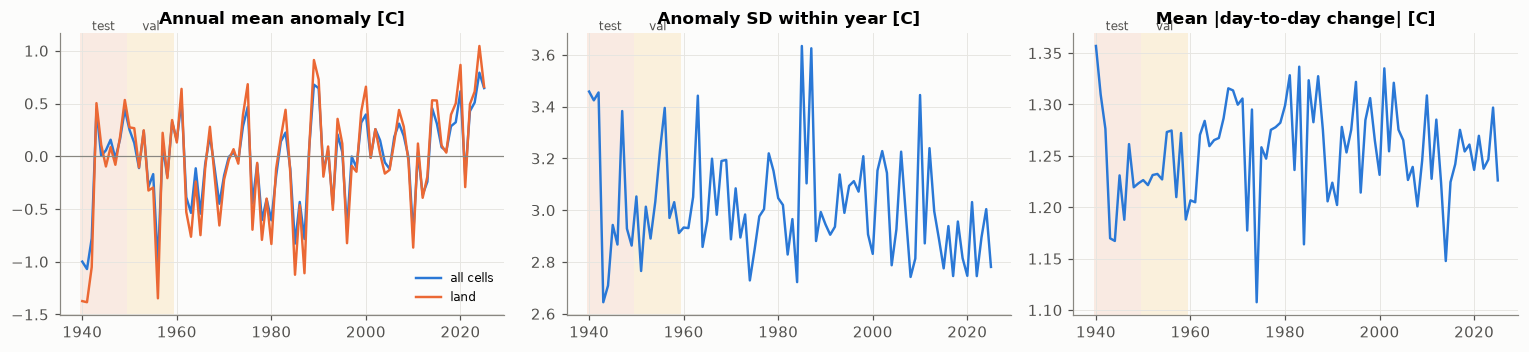

In [8]:
# Year-by-year statistics
yrs = np.unique(YEAR)
dom_mean = np.array([flatA[YEAR == y].mean() for y in yrs])
anom_sd = np.array([flatA[YEAR == y].std() for y in yrs])
land_flat = LAND.ravel()
dom_mean_land = np.array([flatA[YEAR == y][:, land_flat].mean() for y in yrs])
d2d = np.array([np.abs(np.diff(flatA[YEAR == y][:, ::7], axis=0)).mean() for y in yrs])  # day-to-day change

def trend_per_decade(x, y):
    return np.polyfit(x, y, 1)[0] * 10

tr_all = trend_per_decade(yrs, dom_mean)
tr_train = trend_per_decade(yrs[yrs >= TRAIN_YEARS[0]], dom_mean[yrs >= TRAIN_YEARS[0]])
tr_land = trend_per_decade(yrs, dom_mean_land)
print(f"domain-mean trend 1940-2025: {tr_all:+.3f} C/decade (land {tr_land:+.3f}); train years only: {tr_train:+.3f}")
print("for reference: raw European warming 1960-2025 is ~+0.3 to +0.5 C/decade")
if abs(tr_all) > 0.05 or abs(tr_train) > 0.05:
    flag("WARN", f"Residual trend in 'de-warmed' ERA5: {tr_all:+.2f} C/decade (1940-2025), {tr_train:+.2f} (train).")
else:
    flag("INFO", f"De-warming looks effective in the domain mean: {tr_all:+.3f} C/decade 1940-2025.")

test_m, rest_m = in_test, in_train
sd_ratio = flatA[test_m].std() / flatA[rest_m].std()
mean_off = flatA[test_m].mean() - flatA[rest_m].mean()
d2d_ratio = d2d[yrs <= TEST_YEARS[1]].mean() / d2d[yrs >= TRAIN_YEARS[0]].mean()
print(f"1940s vs train: mean offset {mean_off:+.2f} C, anomaly-SD ratio {sd_ratio:.3f}, day-to-day-change ratio {d2d_ratio:.3f}")
if abs(mean_off) > 0.3 or abs(sd_ratio - 1) > 0.05 or abs(d2d_ratio - 1) > 0.05:
    flag("WARN", f"Test decade (1940s) differs from train: offset {mean_off:+.2f} C, variability ratio {sd_ratio:.2f}, "
                 f"day-to-day ratio {d2d_ratio:.2f}. Early ERA5 is less constrained by observations, so test errors "
                 "partly measure 1940s-vs-train mismatch, not just reconstruction skill.")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.3))
ax[0].plot(yrs, dom_mean, color=C[0], label="all cells"); ax[0].plot(yrs, dom_mean_land, color=C[1], label="land")
ax[0].axhline(0, color="#898781", lw=.8); ax[0].set_title("Annual mean anomaly [C]"); ax[0].legend(frameon=False, fontsize=8)
ax[1].plot(yrs, anom_sd, color=C[0]); ax[1].set_title("Anomaly SD within year [C]")
ax[2].plot(yrs, d2d, color=C[0]); ax[2].set_title("Mean |day-to-day change| [C]")
for a in ax: shade_splits(a)
plt.tight_layout()

DJF: domain-mean residual trend +0.084 C/decade


MAM: domain-mean residual trend +0.050 C/decade


JJA: domain-mean residual trend +0.033 C/decade


SON: domain-mean residual trend +0.035 C/decade
pixel trends: 1st-99th pct -0.01..+0.15 C/decade


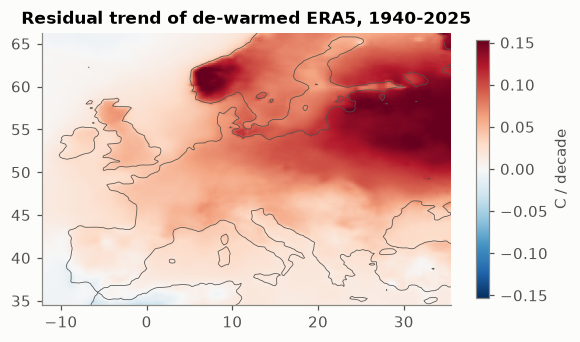

In [9]:
# Residual trend map (per-pixel, annual means 1940-2025) and seasonal trends
ann = np.stack([flatA[YEAR == y].mean(0) for y in yrs])          # (nyr, ncell)
X = np.c_[yrs - yrs.mean(), np.ones_like(yrs)].astype(float)
slope = (np.linalg.lstsq(X, ann, rcond=None)[0][0] * 10).reshape(NLAT, NLON)
seas = {"DJF": [12, 1, 2], "MAM": [3, 4, 5], "JJA": [6, 7, 8], "SON": [9, 10, 11]}
month = DATES.month.values
for s, ms in seas.items():
    m = np.isin(month, ms)
    sm = np.array([flatA[m & (YEAR == y)].mean() for y in yrs])
    print(f"{s}: domain-mean residual trend {trend_per_decade(yrs, sm):+.3f} C/decade")
lim = np.nanpercentile(np.abs(slope), 99)
fig, ax = plt.subplots(figsize=(6, 3.8))
im = ax.imshow(slope, extent=[LON[0], LON[-1], LAT[-1], LAT[0]], cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim, lim))
ax.contour(LON, LAT, LSM, [0.5], colors="#52514e", linewidths=.5); ax.grid(False)
plt.colorbar(im, ax=ax, shrink=.8, label="C / decade"); ax.set_title("Residual trend of de-warmed ERA5, 1940-2025")
print(f"pixel trends: 1st-99th pct {np.percentile(slope, 1):+.2f}..{np.percentile(slope, 99):+.2f} C/decade")
if np.percentile(np.abs(slope), 95) > 0.15:
    flag("WARN", "De-warming leaves spatially structured trends (|trend| > 0.15 C/decade in >5% of cells). "
                 "A domain-mean de-warming can still leave regional/seasonal trends the model will learn as 'climate'.")

global z-score: mean 9.48 C, sd 8.74 C -> z range ~[-5.1, 3.4]
per-cell anomaly SD: 0.99..5.29 C (ratio 5.3x)


anomaly skewness -1.30..+0.81; excess kurtosis -0.38..+5.27
[INFO] Per-cell anomaly SD varies 5x across the domain (sea vs continental interior), and anomalies are skewed (cold-tail in winter continental cells). With one global z-score, sea cells are almost noise-free targets and continental cells carry most of the loss.


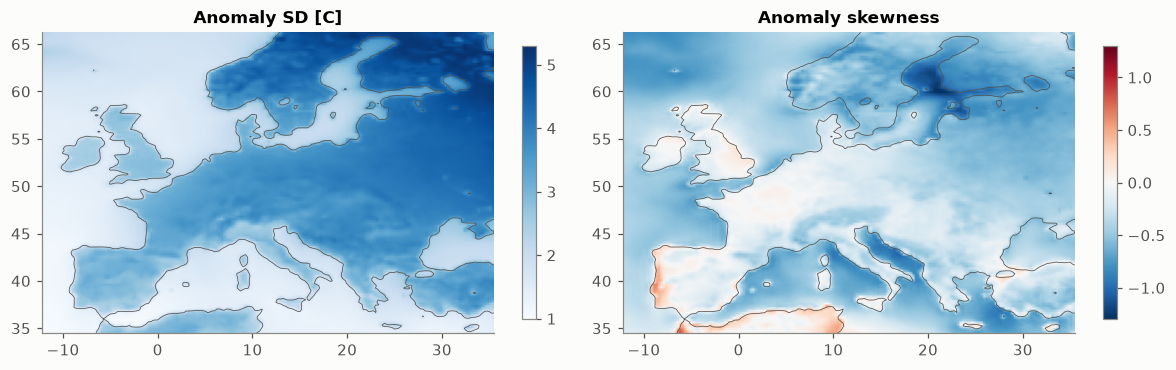

In [10]:
# Normalisation: what the single global z-score produces
t_mean = float(flatA[in_train].mean() + (Hm[in_train].mean(0) @ CLIM_COEF).mean())
raw_train_sd = float(np.sqrt(tot_var))
cell_sd = flatA[in_train].std(0).reshape(NLAT, NLON)
samp = np.where(in_train)[0][::50]
zz = (clim(DOLY[samp]) + A[samp] - t_mean) / raw_train_sd
z_lo, z_hi = zz.min(), zz.max(); del zz
print(f"global z-score: mean {t_mean:.2f} C, sd {raw_train_sd:.2f} C -> z range ~[{z_lo:.1f}, {z_hi:.1f}]")
print(f"per-cell anomaly SD: {cell_sd.min():.2f}..{cell_sd.max():.2f} C (ratio {cell_sd.max()/cell_sd.min():.1f}x)")

sub = flatA[np.where(in_train)[0][::5]]
skew = (((sub - sub.mean(0)) ** 3).mean(0) / sub.std(0) ** 3).reshape(NLAT, NLON)
kurt = (((sub - sub.mean(0)) ** 4).mean(0) / sub.std(0) ** 4 - 3).reshape(NLAT, NLON)
print(f"anomaly skewness {skew.min():+.2f}..{skew.max():+.2f}; excess kurtosis {kurt.min():+.2f}..{kurt.max():+.2f}")
flag("INFO", f"Per-cell anomaly SD varies {cell_sd.max()/cell_sd.min():.0f}x across the domain (sea vs continental "
             "interior), and anomalies are skewed (cold-tail in winter continental cells). With one global z-score, "
             "sea cells are almost noise-free targets and continental cells carry most of the loss.")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
im = ax[0].imshow(cell_sd, extent=[LON[0], LON[-1], LAT[-1], LAT[0]], cmap="Blues"); ax[0].set_title("Anomaly SD [C]")
plt.colorbar(im, ax=ax[0], shrink=.8)
lim = np.abs(skew).max()
im = ax[1].imshow(skew, extent=[LON[0], LON[-1], LAT[-1], LAT[0]], cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim, lim))
ax[1].set_title("Anomaly skewness"); plt.colorbar(im, ax=ax[1], shrink=.8)
for a in ax: a.grid(False); a.contour(LON, LAT, LSM, [0.5], colors="#52514e", linewidths=.5)
plt.tight_layout()

## 3. How many *independent* samples are there?

The training set has about 24k daily fields, but consecutive days are strongly correlated. Two numbers matter for a 16.5M-parameter generative model:
- the **effective** sample size;
- how similar a validation day is to its nearest training day. This is mostly a concern for random splits; here the split is by year block, which is good.

domain-mean ACF still 0.08 at lag 60: low-frequency memory (residual trend/interannual); its time scale below is a lower bound
per-cell lag-1 autocorrelation: median 0.81 (IQR 0.79-0.83)
pattern correlation day t vs t+1: 0.76, t+3: 0.37, t+7: 0.16
integral time scale: domain mean 22.1 d, field pattern 7.7 d
N train = 24107 days -> effective N ~ 3,143 (field pattern) / 1,090 (domain mean)
[WARN] Training set: 24,107 days but only ~3,143 effectively independent fields (pattern correlation t/t+1 = 0.76). 16.5M parameters vs ~3k independent samples is a memorisation-risk regime: check generated samples against their nearest training field.
[INFO] Val/test are contiguous year blocks (good). The 1959/1960 train-val boundary leaks only a few days.


Text(0.5, 1.0, 'How fast do daily fields decorrelate?')

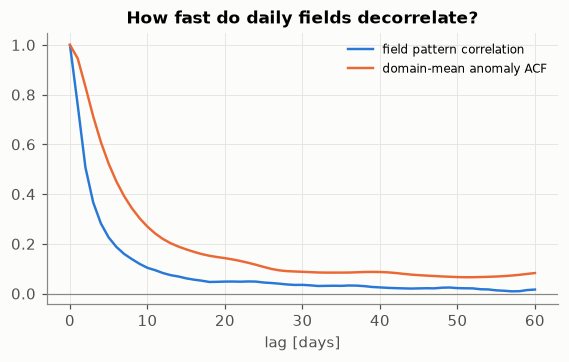

In [11]:
def acf(x, maxlag):
    x = x - x.mean()
    return np.array([1.0] + [np.corrcoef(x[:-k], x[k:])[0, 1] for k in range(1, maxlag + 1)])

lags = 60
# Pattern correlation between the anomaly field on day t and day t+k (how 'new' is the next sample?)
tr_idx = np.where(in_train)[0]
pc = []
sub_cells = flatA[:, ::4]
for k in range(0, lags + 1):
    a, b = sub_cells[tr_idx[:-k or None][::3]], sub_cells[tr_idx[k:][::3]]
    a = a - a.mean(1, keepdims=True); b = b - b.mean(1, keepdims=True)
    pc.append(np.mean((a * b).sum(1) / np.sqrt((a * a).sum(1) * (b * b).sum(1))))
pc = np.array(pc)

# Per-cell lag-1 autocorrelation and integral time scale
x0, x1 = flatA[:, ::16][tr_idx[:-1]], flatA[:, ::16][tr_idx[1:]]
r1 = ((x0 - x0.mean(0)) * (x1 - x1.mean(0))).mean(0) / (x0.std(0) * x1.std(0))
dm = flatA[tr_idx].mean(1)
acf_dm = acf(dm, lags)
def integral_scale(r):
    cut = np.argmax(r < 0.05) if (r < 0.05).any() else len(r)   # sum up to first drop below 0.05
    return 1 + 2 * r[1:cut].sum(), cut < len(r)
tau, dm_crossed = integral_scale(acf_dm)
tau_pc, _ = integral_scale(pc)
if not dm_crossed:
    print(f"domain-mean ACF still {acf_dm[-1]:.2f} at lag {lags}: low-frequency memory (residual trend/interannual); "
          "its time scale below is a lower bound")
N = in_train.sum()
print(f"per-cell lag-1 autocorrelation: median {np.median(r1):.2f} (IQR {np.percentile(r1,25):.2f}-{np.percentile(r1,75):.2f})")
print(f"pattern correlation day t vs t+1: {pc[1]:.2f}, t+3: {pc[3]:.2f}, t+7: {pc[7]:.2f}")
print(f"integral time scale: domain mean {tau:.1f} d, field pattern {tau_pc:.1f} d")
print(f"N train = {N} days -> effective N ~ {N/tau_pc:,.0f} (field pattern) / {N/tau:,.0f} (domain mean)")
N_EFF = N / tau_pc
flag("WARN", f"Training set: {N:,} days but only ~{N_EFF:,.0f} effectively independent fields (pattern correlation "
             f"t/t+1 = {pc[1]:.2f}). 16.5M parameters vs ~{N_EFF/1e3:.0f}k independent samples is a memorisation-risk "
             "regime: check generated samples against their nearest training field.")
flag("INFO", "Val/test are contiguous year blocks (good). The 1959/1960 train-val boundary leaks only a few days.")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(np.arange(lags + 1), pc, color=C[0], label="field pattern correlation")
ax.plot(np.arange(lags + 1), acf_dm, color=C[1], label="domain-mean anomaly ACF")
ax.axhline(0, color="#898781", lw=.8); ax.set_xlabel("lag [days]"); ax.legend(frameon=False, fontsize=8)
ax.set_title("How fast do daily fields decorrelate?")

## 4. Intrinsic dimensionality of the anomaly fields

Count how many EOFs (principal components) are needed to explain most of the daily anomaly variance. If a few dozen modes capture ~90%, the "manifold" is low-dimensional. Two consequences:
- Linear methods (EOF regression, optimal interpolation) are strong baselines.
- A diffusion model's main extra value is its error-free sampling of the small-scale, non-Gaussian rest.

The analysis uses 2×2 coarsened fields with √cos(lat) area weights.

EOFs needed: {'80%': 8, '90%': 20, '95%': 46, '99%': 262}
[INFO] Daily anomalies are low-dimensional: 20 EOFs explain 90%, 46 explain 95%, 262 explain 99% of variance (vs ~3,143 independent training samples).


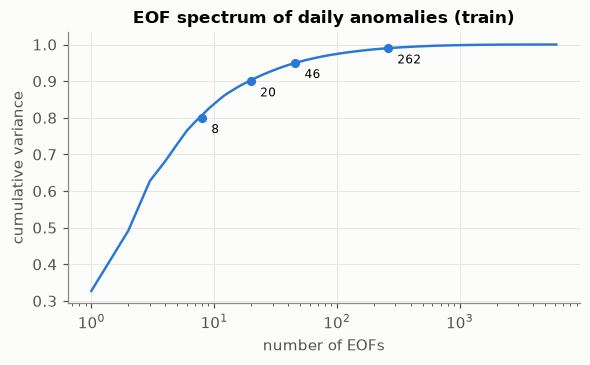

In [12]:
co = A[np.where(in_train)[0][::2]].reshape(-1, NLAT // 2, 2, NLON // 2, 2).mean((2, 4))
w = np.sqrt(np.cos(np.deg2rad(LAT.reshape(-1, 2).mean(1))))[None, :, None]
Xe = (co * w).reshape(len(co), -1)
Xe = Xe - Xe.mean(0)
_, s, _ = np.linalg.svd(Xe, full_matrices=False)
ev = s**2 / (s**2).sum()
cum = np.cumsum(ev)
nmodes = {q: int(np.searchsorted(cum, q) + 1) for q in (0.8, 0.9, 0.95, 0.99)}
print("EOFs needed:", {f"{int(q*100)}%": n for q, n in nmodes.items()})
flag("INFO", f"Daily anomalies are low-dimensional: {nmodes[0.9]} EOFs explain 90%, {nmodes[0.95]} explain 95%, "
             f"{nmodes[0.99]} explain 99% of variance (vs ~{N_EFF:,.0f} independent training samples).")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.semilogx(np.arange(1, len(cum) + 1), cum, color=C[0])
for q, n in nmodes.items():
    ax.plot(n, q, "o", color=C[0], ms=5); ax.annotate(f"{n}", (n, q), textcoords="offset points", xytext=(6, -10), fontsize=8)
ax.set_xlabel("number of EOFs"); ax.set_ylabel("cumulative variance"); ax.set_title("EOF spectrum of daily anomalies (train)")
del co, Xe

## 5. Historical stations: metadata, grid mapping, placement

In [13]:
meta = pd.read_csv(DATA_DIR / "hist_obs_metadata.csv", header=None, names=["id", "c1", "c2"])
in_dom = lambda la, lo: ((la >= LAT.min()) & (la <= LAT.max()) & (lo >= LON.min()) & (lo <= LON.max())).sum()
print(f"documented order (id, lat, lon): {in_dom(meta.c1, meta.c2)}/{len(meta)} stations inside the ERA5 domain")
print(f"swapped order   (id, lon, lat): {in_dom(meta.c2, meta.c1)}/{len(meta)} stations inside the ERA5 domain")
meta = meta.rename(columns={"c1": "lon", "c2": "lat"})
flag("WARN", "hist_obs_metadata.csv has NO header and columns are (id, lon, lat), contrary to the xlsx summary "
             "(id, lat, lon). Fixed in the code; fix the documentation too.")

ids = h_ds.id.values.astype(int)
assert np.array_equal(ids, meta.id.values), "hist_obs id order != metadata order"
li = np.round((LAT[0] - meta.lat.values) / 0.25).astype(int)
lo = np.round((meta.lon.values - LON[0]) / 0.25).astype(int)
snap = np.abs(LAT[li] - meta.lat.values).max() + np.abs(LON[lo] - meta.lon.values).max()
cell = li * NLON + lo
print(f"max snap distance to grid centre: {snap:.4f} deg | unique cells: {len(np.unique(cell))}/{len(cell)}")
st_lsm, st_elev = LSM[li, lo], ELEV[li, lo]
n_sea = int((st_lsm < 0.5).sum())
print(f"station cells with lsm<0.5: {n_sea}; lsm<0.99 (coastal): {(st_lsm < 0.99).sum()}; elevation of station cells "
      f"{st_elev.min():.0f}..{st_elev.max():.0f} m (median {np.median(st_elev):.0f})")
flag("INFO", "Station coordinates are grid-cell centres ('grid-cell id'): stations were pre-aggregated to ERA5 cells, "
             "one station per cell. Point-vs-cell representativeness (esp. mountains/coasts) is not handled.")
if n_sea:
    flag("WARN", f"{n_sea} station cell(s) have lsm < 0.5 (mostly sea). Their ERA5 value is a sea/coast mix, "
                 "so conditioning there injects a land observation into a sea-dominated cell.")

documented order (id, lat, lon): 0/634 stations inside the ERA5 domain
swapped order   (id, lon, lat): 634/634 stations inside the ERA5 domain
[WARN] hist_obs_metadata.csv has NO header and columns are (id, lon, lat), contrary to the xlsx summary (id, lat, lon). Fixed in the code; fix the documentation too.
max snap distance to grid centre: 0.0000 deg | unique cells: 634/634
station cells with lsm<0.5: 96; lsm<0.99 (coastal): 397; elevation of station cells -4..2426 m (median 163)
[INFO] Station coordinates are grid-cell centres ('grid-cell id'): stations were pre-aggregated to ERA5 cells, one station per cell. Point-vs-cell representativeness (esp. mountains/coasts) is not handled.
[WARN] 96 station cell(s) have lsm < 0.5 (mostly sea). Their ERA5 value is a sea/coast mix, so conditioning there injects a land observation into a sea-dominated cell.


hist_obs (99710, 634), 10.9% non-missing, values -38.7..35.8 C


,era,label,mean st/day,median,frac 0 st,frac <5 st,stations ever
0,1667-1746,sparse,3.234,2.0,0.0,0.73,27
1,1747-1766,growing,12.810,14.0,0.0,0.00,24
2,1767-1846,dense,29.559,31.0,0.0,0.00,82
3,1847-1939,very dense,171.469,150.0,0.0,0.00,594


days with ZERO stations: 0 (0.0%)


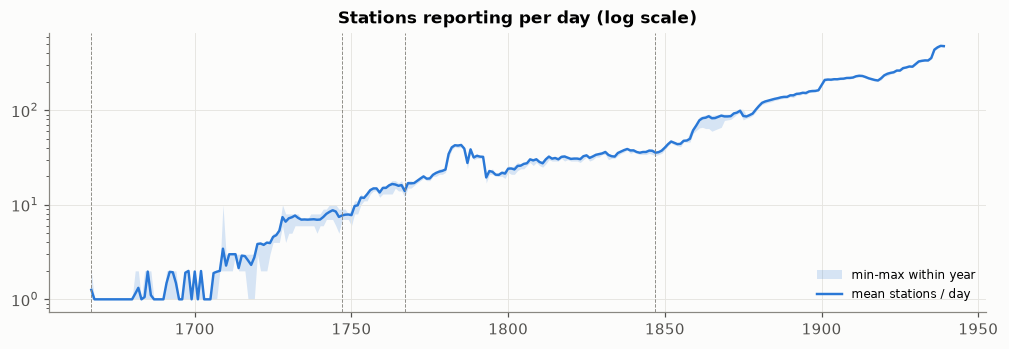

In [14]:
H = h_ds.hist_obs.transpose("day_index", "id").values.astype(np.float32)   # (ndays, nstation)
HDATES = T0 + pd.to_timedelta(h_di - 1, unit="D")
HYEAR = HDATES.year.values
HDOLY = np.asarray(day_of_leap_year(HDATES))
obs = np.isfinite(H)
print(f"hist_obs {H.shape}, {obs.mean():.1%} non-missing, values {np.nanmin(H):.1f}..{np.nanmax(H):.1f} C")

n_per_day = obs.sum(1)
hyrs = np.unique(HYEAR)
yr_mean = np.array([n_per_day[HYEAR == y].mean() for y in hyrs])
yr_min = np.array([n_per_day[HYEAR == y].min() for y in hyrs])
yr_max = np.array([n_per_day[HYEAR == y].max() for y in hyrs])
zero_days = int((n_per_day == 0).sum())
ERAS = [(1667, 1746, "sparse"), (1747, 1766, "growing"), (1767, 1846, "dense"), (1847, 1939, "very dense")]
rows = []
for a, b, name in ERAS:
    m = (HYEAR >= a) & (HYEAR <= b)
    rows.append([f"{a}-{b}", name, n_per_day[m].mean(), np.median(n_per_day[m]), (n_per_day[m] == 0).mean(),
                 (n_per_day[m] < 5).mean(), (obs[m].any(0)).sum()])
era_tab = pd.DataFrame(rows, columns=["era", "label", "mean st/day", "median", "frac 0 st", "frac <5 st", "stations ever"])
display(era_tab.round(3))
print(f"days with ZERO stations: {zero_days} ({zero_days/len(H):.1%})")
if zero_days:
    flag("WARN", f"{zero_days:,} historical days ({zero_days/len(H):.1%}) have no observation at all. For these the "
                 "'reconstruction' is a pure unconditional sample; label or exclude them in any evaluation.")

fig, ax = plt.subplots(figsize=(11, 3.3))
ax.fill_between(hyrs, np.maximum(yr_min, .8), yr_max, color=C[0], alpha=.18, lw=0, label="min-max within year")
ax.plot(hyrs, yr_mean, color=C[0], label="mean stations / day")
ax.set_yscale("log"); ax.set_title("Stations reporting per day (log scale)"); ax.legend(frameon=False, fontsize=8)
for a, b, n in ERAS: ax.axvline(a, color="#898781", lw=.6, ls="--")

stations with no data at all: 0 | median lifespan 19 y | median completeness within lifespan 95%
stations active in 1939: 494 | starting after 1900: 337


Text(0.5, 1.0, 'Fraction of days each station reports, per year')

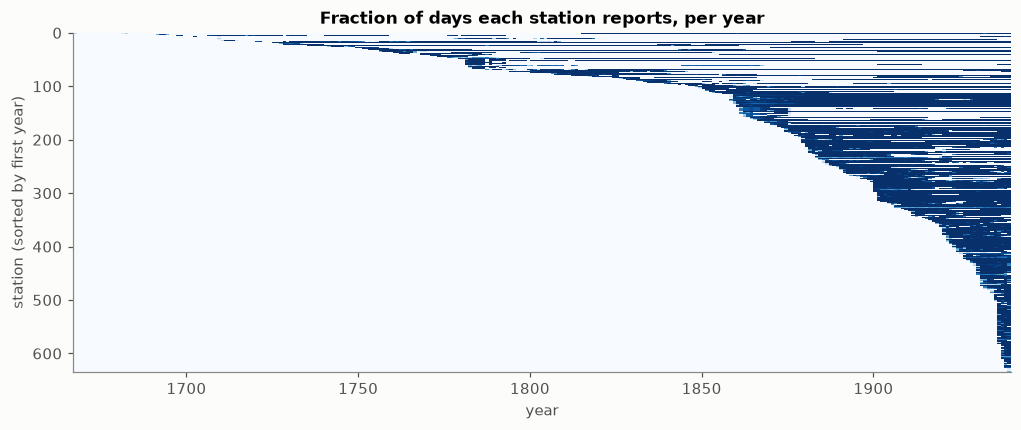

In [15]:
# Station lifespans: coverage per station per year, sorted by first year
cov = np.stack([obs[HYEAR == y].mean(0) for y in hyrs], 1)       # (nstation, nyear)
first = np.array([hyrs[np.argmax(c > 0)] if c.any() else 9999 for c in cov])
last = np.array([hyrs[len(c) - 1 - np.argmax(c[::-1] > 0)] if c.any() else -1 for c in cov])
order = np.argsort(first)
life = last - first + 1
within = np.array([cov[i, (hyrs >= first[i]) & (hyrs <= last[i])].mean() for i in range(len(cov))])
never = int((first == 9999).sum())
print(f"stations with no data at all: {never} | median lifespan {np.median(life):.0f} y | "
      f"median completeness within lifespan {np.median(within):.0%}")
print(f"stations active in 1939: {(cov[:, -1] > 0).sum()} | starting after 1900: {(first > 1900).sum()}")
if never: flag("WARN", f"{never} station(s) in metadata never report.")

fig, ax = plt.subplots(figsize=(11, 4))
ax.imshow(cov[order], aspect="auto", cmap="Blues", extent=[hyrs[0], hyrs[-1] + 1, len(cov), 0], interpolation="nearest")
ax.set_xlabel("year"); ax.set_ylabel("station (sorted by first year)"); ax.grid(False)
ax.set_title("Fraction of days each station reports, per year")

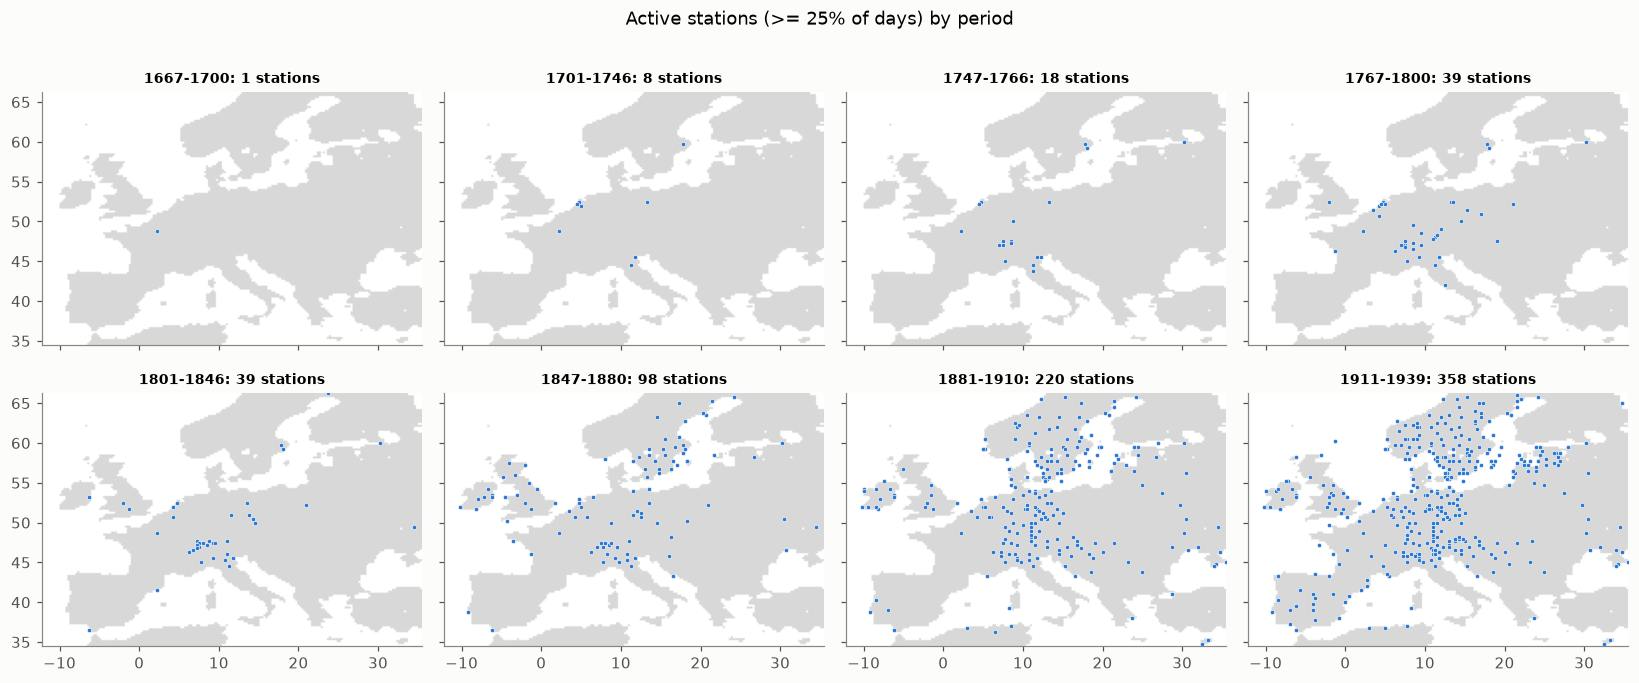

In [16]:
# Where are the stations? Spatial distribution by era (active = reports on >= 25% of days in the window)
snapshots = [(1667, 1700), (1701, 1746), (1747, 1766), (1767, 1800), (1801, 1846), (1847, 1880), (1881, 1910), (1911, 1939)]
fig, axs = plt.subplots(2, 4, figsize=(15, 6.2), sharex=True, sharey=True)
for ax, (a, b) in zip(axs.ravel(), snapshots):
    m = (HYEAR >= a) & (HYEAR <= b)
    act = obs[m].mean(0) >= 0.25
    ax.imshow(LAND, extent=[LON[0], LON[-1], LAT[-1], LAT[0]], cmap="Greys", vmin=0, vmax=4)
    ax.scatter(meta.lon[act], meta.lat[act], s=8, color=C[0], edgecolor="#fcfcfb", linewidth=.4)
    ax.set_title(f"{a}-{b}: {act.sum()} stations", fontsize=9); ax.grid(False)
plt.suptitle("Active stations (>= 25% of days) by period", y=1.0); plt.tight_layout()

,decade,n_active,land<250km,land<500km,lat_c,lon_c,median_dist_km
0,1670,1,0.03,0.09,48.75,2.25,1526.33
3,1700,2,0.04,0.12,50.50,3.38,1349.54
6,1730,9,0.12,0.34,51.03,8.36,689.55
9,1760,19,0.18,0.45,49.70,10.59,556.57
12,1790,33,0.31,0.62,49.15,9.96,395.38
15,1820,36,0.34,0.74,49.10,10.76,343.87
18,1850,55,0.43,0.78,50.25,10.10,287.02
21,1880,147,0.66,0.93,52.93,12.19,172.91
24,1910,244,0.80,1.00,52.80,12.44,122.35


[WARN] Spatial coverage, not just station count, changes over time: 21% of land within 500 km of a station before 1750 vs 99% after 1900, and the network centroid drifts. Skill estimates averaged over the whole domain mix 'near stations' and 'far from everything'; stratify by distance.


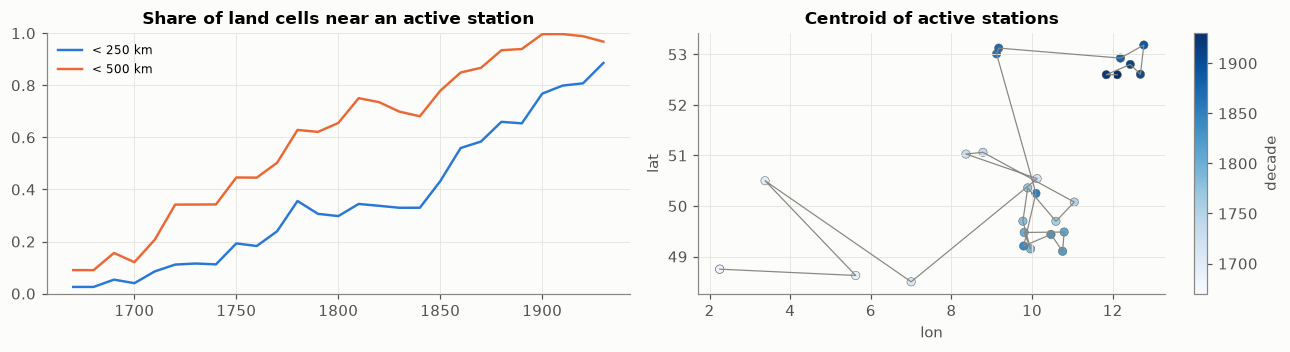

In [17]:
# Coverage: fraction of land cells within R km of an active station, by decade; and the centroid drift
def haversine_min(lat_c, lon_c, lat_s, lon_s, chunk=4000):
    out = np.empty(len(lat_c))
    la_s, lo_s = np.deg2rad(lat_s)[None], np.deg2rad(lon_s)[None]
    for i in range(0, len(lat_c), chunk):
        la, lo_ = np.deg2rad(lat_c[i:i+chunk])[:, None], np.deg2rad(lon_c[i:i+chunk])[:, None]
        d = 2 * 6371 * np.arcsin(np.sqrt(np.sin((la - la_s) / 2)**2 + np.cos(la) * np.cos(la_s) * np.sin((lo_ - lo_s) / 2)**2))
        out[i:i+chunk] = d.min(1)
    return out

LLAT, LLON = np.meshgrid(LAT, LON, indexing="ij")
land_lat, land_lon = LLAT[LAND], LLON[LAND]
decs = np.arange(1670, 1940, 10)
cov_rows = []
for d0 in decs:
    m = (HYEAR >= d0) & (HYEAR < d0 + 10)
    act = obs[m].mean(0) >= 0.25
    if act.sum() == 0:
        cov_rows.append([d0, 0, 0, 0, np.nan, np.nan, np.inf]); continue
    dist = haversine_min(land_lat, land_lon, meta.lat.values[act], meta.lon.values[act])
    cov_rows.append([d0, act.sum(), (dist < 250).mean(), (dist < 500).mean(),
                     meta.lat[act].mean(), meta.lon[act].mean(), np.median(dist)])
cov_tab = pd.DataFrame(cov_rows, columns=["decade", "n_active", "land<250km", "land<500km", "lat_c", "lon_c", "median_dist_km"])
display(cov_tab.round(2).iloc[::3])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.3))
ax[0].plot(cov_tab.decade, cov_tab["land<250km"], color=C[0], label="< 250 km")
ax[0].plot(cov_tab.decade, cov_tab["land<500km"], color=C[1], label="< 500 km")
ax[0].set_title("Share of land cells near an active station"); ax[0].legend(frameon=False, fontsize=8); ax[0].set_ylim(0, 1)
ax[1].plot(cov_tab.lon_c, cov_tab.lat_c, "-", color="#898781", lw=.8)
sc = ax[1].scatter(cov_tab.lon_c, cov_tab.lat_c, c=cov_tab.decade, cmap="Blues", s=30, edgecolor="#52514e", lw=.3)
plt.colorbar(sc, ax=ax[1], label="decade"); ax[1].set_title("Centroid of active stations"); ax[1].set_xlabel("lon"); ax[1].set_ylabel("lat")
plt.tight_layout()
lo_cov = cov_tab[cov_tab.decade < 1750]["land<500km"].mean()
hi_cov = cov_tab[cov_tab.decade >= 1900]["land<500km"].mean()
flag("WARN", f"Spatial coverage, not just station count, changes over time: {lo_cov:.0%} of land within 500 km of a "
             f"station before 1750 vs {hi_cov:.0%} after 1900, and the network centroid drifts. Skill estimates "
             "averaged over the whole domain mix 'near stations' and 'far from everything'; stratify by distance.")

## 6. Historical observation values: plausibility, consistency with ERA5, calendar

The model is trained only on ERA5, but at inference it is conditioned on station values. Any **systematic offset** between station data and the ERA5 cell climate gets pasted into the field as if it were weather. Sources of offset:
- point-vs-cell representativeness;
- inconsistent de-warming;
- uncorrected instruments or calendar.

stations with >= 2 years data: 608
annual-mean bias station - ERA5 cell: median +0.20 C, IQR +0.06..+0.43, |bias|>2C: 0, |bias|>4C: 0
seasonal amplitude ratio station/ERA5: median 1.00, range 0.85..1.18


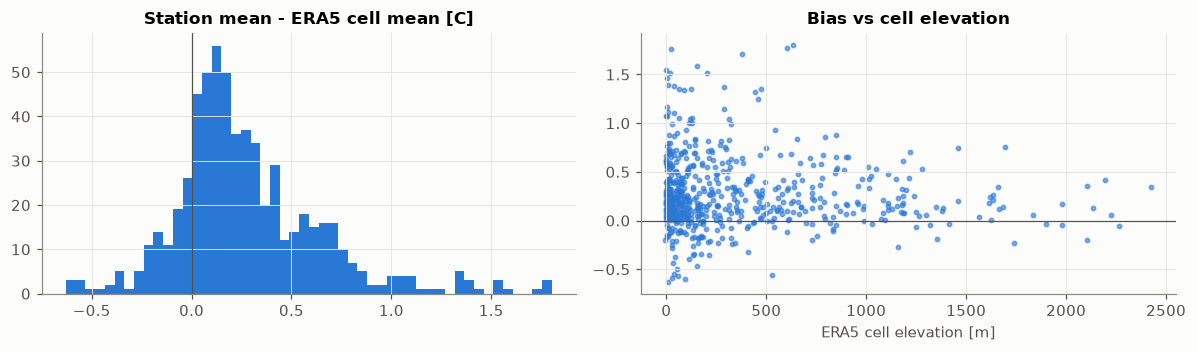

In [18]:
# Per-station harmonic fit (mean + 3 harmonics) over its whole record
Hh = harmonics(HDOLY)
st_coef = np.full((H.shape[1], Hh.shape[1]), np.nan)
resid = np.full_like(H, np.nan)
for s in range(H.shape[1]):
    m = obs[:, s]
    if m.sum() < 730: continue
    st_coef[s] = np.linalg.lstsq(Hh[m], H[m, s], rcond=None)[0]
    resid[m, s] = H[m, s] - Hh[m] @ st_coef[s]

era_coef_at_st = CLIM_COEF[:, cell].T      # ERA5 (train-year) climatology at station cells
ok = np.isfinite(st_coef[:, 0])
bias = st_coef[ok, 0] - era_coef_at_st[ok, 0]
amp_st = np.hypot(st_coef[ok, 1], st_coef[ok, 2]); amp_era = np.hypot(era_coef_at_st[ok, 1], era_coef_at_st[ok, 2])
print(f"stations with >= 2 years data: {ok.sum()}")
print(f"annual-mean bias station - ERA5 cell: median {np.median(bias):+.2f} C, IQR {np.percentile(bias,25):+.2f}..{np.percentile(bias,75):+.2f}, "
      f"|bias|>2C: {(np.abs(bias)>2).sum()}, |bias|>4C: {(np.abs(bias)>4).sum()}")
print(f"seasonal amplitude ratio station/ERA5: median {np.median(amp_st/amp_era):.2f}, range {np.min(amp_st/amp_era):.2f}..{np.max(amp_st/amp_era):.2f}")
if (np.abs(bias) > 2).sum():
    flag("WARN", f"{(np.abs(bias)>2).sum()} stations differ from their ERA5 cell climatology by >2 C in the long-term "
                 f"mean (median bias {np.median(bias):+.2f} C). In replacement inpainting this offset is injected as a "
                 "local anomaly. Conditioning on station ANOMALIES (station value minus station climatology, plus ERA5 "
                 "cell climatology) would remove it.")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].hist(bias, bins=50, color=C[0]); ax[0].set_title("Station mean - ERA5 cell mean [C]"); ax[0].axvline(0, color="#52514e", lw=.8)
ax[1].scatter(st_elev[ok], bias, s=8, color=C[0], alpha=.6); ax[1].set_xlabel("ERA5 cell elevation [m]")
ax[1].set_title("Bias vs cell elevation"); ax[1].axhline(0, color="#52514e", lw=.8)
plt.tight_layout()

In [19]:
# Outliers, stuck values, implausible jumps
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    rsd = np.nanstd(resid, 0)
z = resid / rsd
n_z6 = int(np.nansum(np.abs(z) > 6))
jump = np.abs(np.diff(H, axis=0))
n_jump = int(np.nansum(jump > 20))
eq = H[1:] == H[:-1]                                   # NaN == NaN is False
stuck = int((eq[:-3] & eq[1:-2] & eq[2:-1] & eq[3:]).any(0).sum())   # 5 identical values in a row
print(f"|z| > 6 vs own seasonal cycle: {n_z6} values | day-to-day jumps > 20 C: {n_jump} | stations with >= 5 identical "
      f"consecutive values: {stuck}")
vals, cnts = np.unique(np.round(H[obs], 2), return_counts=True)
print(f"distinct values at 0.01 C resolution: {len(vals):,}; most frequent {vals[cnts.argmax()]:.2f} C ({cnts.max()}x, "
      f"expected ~{obs.sum()/len(vals):.0f}x if uniform): no fill value apparent")
if n_z6 or n_jump:
    flag("WARN", f"Outlier candidates in hist_obs: {n_z6} values with |z|>6, {n_jump} jumps > 20 C/day. Review before "
                 "using them as hard constraints: inpainting forces the field to pass through them.")
if stuck:
    flag("WARN", f"{stuck} stations have runs of >= 5 identical consecutive values (stuck/filled data?).")

|z| > 6 vs own seasonal cycle: 130 values | day-to-day jumps > 20 C: 112 | stations with >= 5 identical consecutive values: 0
distinct values at 0.01 C resolution: 6,546; most frequent 13.39 C (3266x, expected ~1050x if uniform): no fill value apparent
[WARN] Outlier candidates in hist_obs: 130 values with |z|>6, 112 jumps > 20 C/day. Review before using them as hard constraints: inpainting forces the field to pass through them.


,window,n_stations,median_lag_d,q25,q75
0,1660,1,-2.0,-2.0,-2.0
1,1680,1,-3.3,-3.3,-3.3
2,1700,4,-1.7,-2.4,-0.3
3,1720,9,-0.9,-2.1,-0.3
4,1740,17,-1.7,-3.1,0.7
5,1760,25,-1.3,-2.6,-0.2
6,1780,48,-1.8,-2.7,-1.0
7,1800,37,-0.8,-1.6,0.6
8,1820,45,-1.2,-1.9,0.1
9,1840,60,-1.1,-2.0,0.1


median phase lag before 1740: -1.9 d, after 1800: -1.1 d
[INFO] No sign of an unconverted Julian calendar (phase lag pre-1740 -1.9 d vs post-1800 -1.1 d).


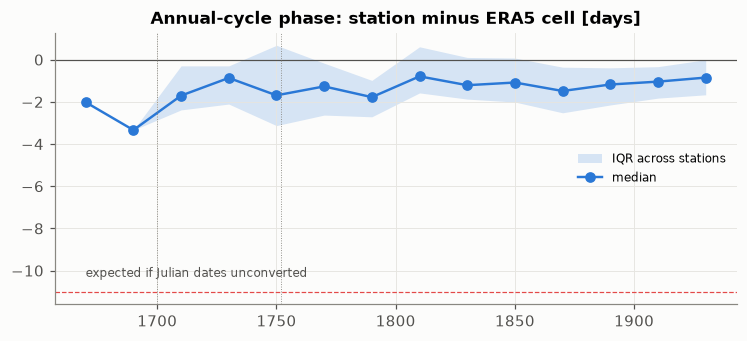

In [20]:
# Calendar check: Julian-dated records left unconverted shift the seasonal cycle by ~10-11 days.
# Fit the annual harmonic per station per 20-year window and compare its phase to the ERA5 cell climatology.
def peak_day(cc, cs):
    return np.mod(np.arctan2(cs, cc), 2 * np.pi) / (2 * np.pi) * 366

era_peak = peak_day(era_coef_at_st[:, 1], era_coef_at_st[:, 2])
win = np.arange(1660, 1940, 20)
lag_rows = []
H1 = harmonics(HDOLY, k=1)
for w0 in win:
    m = (HYEAR >= w0) & (HYEAR < w0 + 20)
    lags_w = []
    for s in range(H.shape[1]):
        mm = m & obs[:, s]
        if mm.sum() < 3 * 365: continue
        c = np.linalg.lstsq(H1[mm], H[mm, s], rcond=None)[0]
        lags_w.append(((peak_day(c[1], c[2]) - era_peak[s] + 183) % 366) - 183)
    if lags_w:
        lags_w = np.array(lags_w)
        lag_rows.append([w0, len(lags_w), np.median(lags_w), np.percentile(lags_w, 25), np.percentile(lags_w, 75)])
lag_tab = pd.DataFrame(lag_rows, columns=["window", "n_stations", "median_lag_d", "q25", "q75"])
display(lag_tab.round(1))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.fill_between(lag_tab.window + 10, lag_tab.q25, lag_tab.q75, color=C[0], alpha=.18, lw=0, label="IQR across stations")
ax.plot(lag_tab.window + 10, lag_tab.median_lag_d, "o-", color=C[0], label="median")
ax.axhline(0, color="#52514e", lw=.8); ax.axhline(-11, color=C[7], lw=.8, ls="--")
ax.text(1670, -10.3, "expected if Julian dates unconverted", fontsize=8, color="#52514e")
for yr in (1700, 1752): ax.axvline(yr, color="#898781", lw=.6, ls=":")
ax.set_title("Annual-cycle phase: station minus ERA5 cell [days]"); ax.legend(frameon=False, fontsize=8)
early = lag_tab[lag_tab.window < 1740].median_lag_d.median(); late = lag_tab[lag_tab.window >= 1800].median_lag_d.median()
print(f"median phase lag before 1740: {early:+.1f} d, after 1800: {late:+.1f} d")
if early - late < -5:
    flag("ISSUE", f"Early records' seasonal cycle peaks {late-early:.0f} days earlier than later ones: possible "
                  "Julian-calendar dates left unconverted.")
else:
    flag("INFO", f"No sign of an unconverted Julian calendar (phase lag pre-1740 {early:+.1f} d vs post-1800 {late:+.1f} d).")

stations 1920-39 mean anomaly +0.35 C | ERA5 1940-59 at station cells -0.15 C | step -0.50 C
stations (debiased) trend 1667-1850: +0.05 C/century
[WARN] Level step of -0.50 C across the 1939/1940 seam: stations (1920-39) sit +0.35 C above the ERA5 training climatology, de-warmed ERA5 (1940-59) -0.15 C. About +0.20 C of it is the typical station-vs-cell offset; the rest suggests hist_obs and the training fields are not on the same de-warmed baseline (STATUS open question (a)). Confirm with the data provider before step 4.


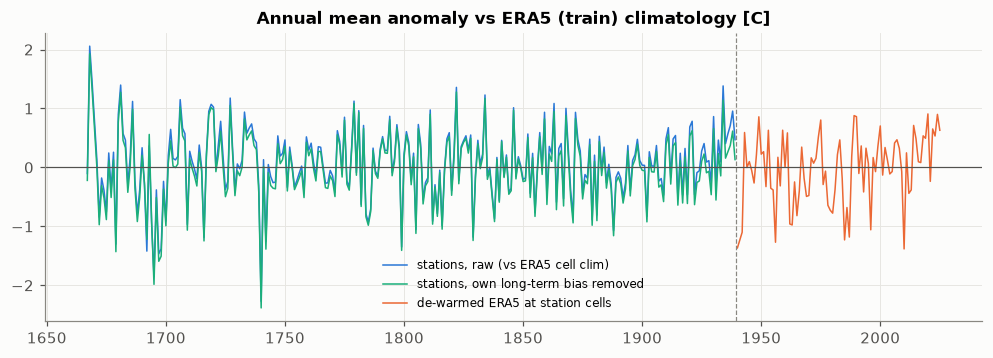

In [21]:
# De-warming consistency across the 1939/1940 seam: anomaly vs ERA5 cell climatology, yearly mean over station cells
clim_st = (Hh @ era_coef_at_st.T)                         # ERA5 climatology at station cells, per historical day
st_anom = np.nanmean(np.where(obs, H - clim_st, np.nan), 1)
st_anom_y = pd.Series(st_anom).groupby(HYEAR).mean()
# Same quantity for ERA5 at station cells active in 1911-1939
act_late = obs[HYEAR >= 1911].mean(0) >= 0.25
era_st_y = pd.Series(flatA[:, cell[act_late]].mean(1)).groupby(YEAR).mean()
# Station-composition-free version: subtract each station's own long-term bias first
st_anom_debiased = np.nanmean(np.where(obs, H - clim_st - (st_coef[:, 0] - era_coef_at_st[:, 0])[None], np.nan), 1)
st_deb_y = pd.Series(st_anom_debiased).groupby(HYEAR).mean()

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(st_anom_y.index, st_anom_y.values, color=C[0], lw=1, label="stations, raw (vs ERA5 cell clim)")
ax.plot(st_deb_y.index, st_deb_y.values, color=C[2], lw=1, label="stations, own long-term bias removed")
ax.plot(era_st_y.index, era_st_y.values, color=C[1], lw=1, label="de-warmed ERA5 at station cells")
ax.axhline(0, color="#52514e", lw=.8); ax.axvline(1939.5, color="#898781", ls="--", lw=.8)
ax.set_title("Annual mean anomaly vs ERA5 (train) climatology [C]"); ax.legend(frameon=False, fontsize=8)
seam_st = st_anom_y.loc[1920:1939].mean(); seam_era = era_st_y.loc[1940:1959].mean()
pre = st_deb_y.loc[1667:1850]; trend_pre = np.polyfit(pre.index, pre.values, 1)[0] * 100
print(f"stations 1920-39 mean anomaly {seam_st:+.2f} C | ERA5 1940-59 at station cells {seam_era:+.2f} C | step {seam_era - seam_st:+.2f} C")
print(f"stations (debiased) trend 1667-1850: {trend_pre:+.2f} C/century")
if abs(seam_era - seam_st) > 0.3:
    flag("WARN", f"Level step of {seam_era - seam_st:+.2f} C across the 1939/1940 seam: stations (1920-39) sit "
                 f"{seam_st:+.2f} C above the ERA5 training climatology, de-warmed ERA5 (1940-59) {seam_era:+.2f} C. "
                 f"About {np.median(bias):+.2f} C of it is the typical station-vs-cell offset; the rest suggests "
                 "hist_obs and the training fields are not on the same de-warmed baseline (STATUS open question (a)). "
                 "Confirm with the data provider before step 4.")
else:
    flag("INFO", f"No large level step across 1939/1940 ({seam_era - seam_st:+.2f} C), but this can't confirm that "
                 "hist_obs is de-warmed the same way. Ask the data provider.")

## 7. Training vs inference mismatch: the masks

Training never sees a mask, because the model is unconditional. Observations enter only at sampling time, by overwriting the noised field at the station cells. What the data says about that design:
- Conditioning is **1-pixel point constraints**: ~1 to ~360 of 24,576 cells (0.004%–1.5%).
- Replacement inpainting is known to propagate such isolated constraints poorly. The network has never seen a field with an "inconsistent" single pixel, so it largely treats the pixel as noise.
- The masks are spatially clustered and drift over time (§5). A sampler validated on one era's masks doesn't transfer automatically to another.

In [22]:
frac_cells = n_per_day / (NLAT * NLON)
print(f"observed fraction of the grid per day: median {np.median(frac_cells):.4%}, max {frac_cells.max():.3%}")
print(f"station cells as share of LAND cells: {len(np.unique(cell)) / LAND.sum():.2%}")
flag("WARN", f"Conditioning is extremely sparse: median {np.median(n_per_day):.0f} observed cells/day "
             f"({np.median(frac_cells):.3%} of the grid), always at the same {len(np.unique(cell))} cells. Single-pass "
             "replacement inpainting (the default, RePaint off) on isolated pixels propagates information weakly. "
             "This fits STATUS sec. 5: RMSE barely improves with 50x more stations.")

observed fraction of the grid per day: median 0.1261%, max 1.982%
station cells as share of LAND cells: 4.66%
[WARN] Conditioning is extremely sparse: median 31 observed cells/day (0.126% of the grid), always at the same 634 cells. Single-pass replacement inpainting (the default, RePaint off) on isolated pixels propagates information weakly. This fits STATUS sec. 5: RMSE barely improves with 50x more stations.


## 8. Is a diffusion model the right tool here? Cheap baselines on the same test protocol

This mirrors `target_period_sweep.py`:
1. Take a historical day's real station mask.
2. Take a season-matched 1940s ERA5 field (same day-of-leap-year, random 1940s year).
3. Give the method the true 1940s values at the masked cells.
4. Score RMSE over all *unobserved* cells.

The methods use only the training years (1960–2025):

| Baseline | What it does |
|---|---|
| **Climatology** | per-cell seasonal cycle, ignores stations |
| **Random analogue** | a random training field from the same day-of-year, ignores stations. This is roughly what a single *unconditional* diffusion sample scores |
| **Climatology + ridge regression (OI)** | anomaly at every cell regressed on the anomalies at the observed cells, using the training-set anomaly covariance. A linear optimal-interpolation / EOF-regression analogue, a few lines of code |

For reference, the diffusion model scored per era (STATUS §5): 3.99 / 3.98 / 3.96 / 3.83 °C RMSE.

> A single posterior *sample* has an expected MSE of about **2×** the posterior variance, while the posterior *mean* (an ensemble mean, or the linear estimate) has about 1×. So a fair comparison with the deterministic baselines is the diffusion **ensemble mean**, or its single-sample RMSE / √2.

In [23]:
t = time.time()
tr = np.where(in_train)[0][::2]
Xtr = flatA[tr]
COV = (Xtr.T @ Xtr) / len(tr)        # (ncell, ncell) float32, ~2.4 GB
del Xtr
print(f"anomaly covariance from {len(tr)} training days in {time.time()-t:.0f}s")

test_idx = np.where(in_test)[0]
test_by_doly = {d: test_idx[DOLY[test_idx] == d] for d in np.unique(DOLY[test_idx])}
train_idx = np.where(in_train)[0]
train_by_doly = {d: train_idx[DOLY[train_idx] == d] for d in np.unique(DOLY[train_idx])}

def run_case(hday, ridge=1e-2):
    K = np.unique(cell[obs[hday]])
    d = HDOLY[hday]
    if d not in test_by_doly or len(test_by_doly[d]) == 0:
        return None
    ti = RNG.choice(test_by_doly[d])
    truth = flatA[ti]                                     # anomaly vs train climatology
    unobs = np.ones(NLAT * NLON, bool); unobs[K] = False
    land_unobs = unobs & land_flat
    out = {"n_obs": len(K)}
    # climatology: anomaly prediction 0
    out["clim"] = np.sqrt(np.mean(truth[unobs] ** 2)); out["clim_land"] = np.sqrt(np.mean(truth[land_unobs] ** 2))
    # random analogue = unconditional draw
    ai = RNG.choice(train_by_doly[d]); ana = flatA[ai]
    out["analog"] = np.sqrt(np.mean((ana - truth)[unobs] ** 2))
    # ridge / OI
    if len(K):
        Ckk = COV[np.ix_(K, K)]
        lam = ridge * np.trace(Ckk) / len(K)
        wts = np.linalg.solve(Ckk + lam * np.eye(len(K), dtype=np.float32), COV[K])   # (k, ncell)
        pred = truth[K] @ wts
    else:
        pred = np.zeros_like(truth)
    out["ridge"] = np.sqrt(np.mean((pred - truth)[unobs] ** 2)); out["ridge_land"] = np.sqrt(np.mean((pred - truth)[land_unobs] ** 2))
    out["ridge_mae"] = np.mean(np.abs(pred - truth)[unobs])
    # error near vs far from stations (land cells)
    if len(K):
        dist = haversine_min(LLAT.ravel()[land_unobs], LLON.ravel()[land_unobs], LLAT.ravel()[K], LLON.ravel()[K])
        e2 = (pred - truth)[land_unobs] ** 2; c2 = truth[land_unobs] ** 2
        for lo_, hi_ in [(0, 250), (250, 500), (500, 1e9)]:
            mm = (dist >= lo_) & (dist < hi_)
            out[f"ridge_{lo_}"] = np.sqrt(e2[mm].mean()) if mm.any() else np.nan
            out[f"clim_{lo_}"] = np.sqrt(c2[mm].mean()) if mm.any() else np.nan
    return out

N_PER_ERA = 60
res = []
t = time.time()
for a, b, name in ERAS:
    cand = np.where((HYEAR >= a) & (HYEAR <= b))[0]
    for hday in RNG.choice(cand, N_PER_ERA, replace=False):
        r = run_case(hday)
        if r: res.append({"era": f"{a}-{b}", **r})
res = pd.DataFrame(res)
print(f"{len(res)} test cases in {time.time()-t:.0f}s")
summary = res.groupby("era", sort=False)[["n_obs", "clim", "analog", "ridge", "ridge_mae", "clim_land", "ridge_land"]].mean()
summary["diffusion (STATUS)"] = [3.99, 3.98, 3.96, 3.83]
summary["diffusion / sqrt2"] = summary["diffusion (STATUS)"] / np.sqrt(2)
display(summary.round(2))

anomaly covariance from 12054 training days in 13s


240 test cases in 13s


,n_obs,clim,analog,ridge,ridge_mae,clim_land,ridge_land,diffusion (STATUS),diffusion / sqrt2
era,,,,,,,,,
1667-1746,3.47,2.79,3.98,2.28,1.69,3.41,2.72,3.99,2.82
1747-1766,13.12,3.14,4.21,2.12,1.55,3.84,2.55,3.98,2.81
1767-1846,29.32,3.06,4.35,1.82,1.31,3.79,2.13,3.96,2.80
1847-1939,160.43,2.64,3.97,1.10,0.76,3.21,1.21,3.83,2.71


Land-cell RMSE [C] by distance to nearest observed cell:


,clim <250km,ridge <250km,clim 250-500km,ridge 250-500km,clim >500km,ridge >500km
era,,,,,,
1667-1746,3.14,0.89,3.26,1.57,3.39,2.92
1747-1766,3.70,1.14,3.92,1.96,3.76,2.97
1767-1846,3.72,1.08,3.92,1.90,3.58,2.71
1847-1939,3.30,0.81,3.14,1.45,2.59,1.96


[INFO] Baseline RMSE (mean over eras): climatology 2.91, random analogue 4.13, clim+ridge 1.83 C; diffusion (STATUS) 3.93 C.


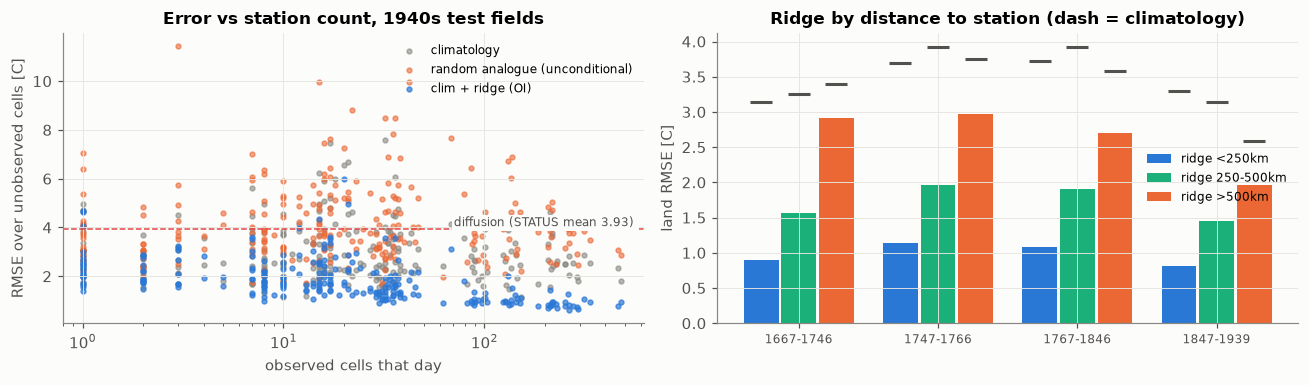

In [24]:
near = res.groupby("era", sort=False)[["clim_0", "ridge_0", "clim_250", "ridge_250", "clim_500", "ridge_500"]].mean()
near.columns = ["clim <250km", "ridge <250km", "clim 250-500km", "ridge 250-500km", "clim >500km", "ridge >500km"]
print("Land-cell RMSE [C] by distance to nearest observed cell:")
display(near.round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].scatter(res.n_obs, res.clim, s=10, color="#898781", alpha=.6, label="climatology")
ax[0].scatter(res.n_obs, res.analog, s=10, color=C[1], alpha=.6, label="random analogue (unconditional)")
ax[0].scatter(res.n_obs, res.ridge, s=10, color=C[0], alpha=.7, label="clim + ridge (OI)")
ax[0].axhline(3.93, color=C[7], ls="--", lw=1)
ax[0].text(0.99, 3.93, "diffusion (STATUS mean 3.93) ", transform=ax[0].get_yaxis_transform(), ha="right", va="bottom",
           fontsize=8, color="#52514e", bbox=dict(fc="#fcfcfb", ec="none", pad=1))
ax[0].set_xscale("log"); ax[0].set_xlim(0.8, res.n_obs.max() * 1.3); ax[0].set_xlabel("observed cells that day"); ax[0].set_ylabel("RMSE over unobserved cells [C]")
ax[0].legend(frameon=False, fontsize=8, loc="upper right"); ax[0].set_title("Error vs station count, 1940s test fields")
x = np.arange(len(near))
for j, (lab, col) in enumerate([("<250km", C[0]), ("250-500km", C[2]), (">500km", C[1])]):
    ax[1].bar(x + (j - 1) * 0.27, near[f"ridge {lab}"], 0.25, color=col, label=f"ridge {lab}")
    ax[1].plot(x + (j - 1) * 0.27, near[f"clim {lab}"], "_", color="#52514e", ms=14, mew=2)
ax[1].set_xticks(x, near.index, fontsize=8); ax[1].set_ylabel("land RMSE [C]"); ax[1].legend(frameon=False, fontsize=8)
ax[1].set_title("Ridge by distance to station (dash = climatology)")
plt.tight_layout()

flag("INFO", "Baseline RMSE (mean over eras): climatology {:.2f}, random analogue {:.2f}, clim+ridge {:.2f} C; "
             "diffusion (STATUS) 3.93 C.".format(summary.clim.mean(), summary.analog.mean(), summary.ridge.mean()))

### Reading §8

Compare three numbers:
- The **diffusion RMSE (~3.9 °C)**.
- The **random analogue**. This is what you get with no conditioning at all, from a single realistic sample.
- **clim + ridge**. This is what a linear method gets from the same station cells.

What the outcomes would mean:
- **Diffusion ≈ random analogue**: the sampler is effectively unconditional, and the stations barely matter.
- **Ridge clearly below diffusion / √2 and improving with station count or nearness**: the information is in the data, and the bottleneck is the conditioning mechanism, not the amount of data.

See the summary at the end for the conclusions from this run.

## 9. Summary and recommendations

### What's fine
- Files are complete and contiguous, the grids are identical, there are no NaNs, and value ranges are plausible.
- The day-of-leap-year encoding matches the code.
- Every historical day has at least one observation.
- Each station sits exactly on a grid-cell centre, one station per cell.
- There's no sign of unconverted Julian-calendar dates.
- Station climatologies match their ERA5 cells closely: median bias about +0.2 °C, seasonal amplitude ratio about 1.0.

### Data issues to handle in any retraining
1. **Training targets are mostly climatology.** About 88% of raw-field variance is the fixed seasonal and spatial pattern. Train on anomalies (or per-pixel standardised fields) and add the climatology back afterwards.
2. **There are few independent samples.** The 24k training days amount to only about 3k effectively independent fields, which is a memorisation-risk regime for 16.5M parameters. Validation loss plateaued at 30% of training, and diffusion validation loss is a poor overfitting detector. `04_diffusion_reevaluation.ipynb` checks this directly and finds no sign of memorisation.
3. **De-warming is imperfect.** A residual trend of about +0.05 °C/decade remains (+0.08 °C/decade in winter), so the 1940s test decade is offset by about −0.16 °C. There is also a level step of about 0.5 °C between stations (1920–39) and ERA5 (1940–59). Clarify whether `hist_obs` is de-warmed like ERA5 before real reconstructions.
4. **The historical masks are a moving target.** Before 1750, about 3 stations/day cover only about 20% of land within 500 km. After 1900, coverage is 99%, and the network centroid drifts. Always report skill stratified by distance to the nearest station, and separately for land and sea.
5. **Small items:**
   - `day_index` is 1-based despite its CF "days since" attribute.
   - The metadata columns are (id, lon, lat), unlike the xlsx summary.
   - 96 station cells are mostly sea (lsm < 0.5).
   - About 130 outlier values and about 110 jumps of more than 20 °C/day should be reviewed, since inpainting treats them as hard constraints.

### Is a diffusion model the right choice?
**The data size isn't the main problem; the conditioning design is.**

§8 shows that the current model's error (3.93 °C) is about the same as drawing a *random* training field for the same calendar day (4.13 °C). It is also worse than plain climatology (2.91 °C). It barely improves with station count. Meanwhile, a 10-line linear regression from the same station cells reaches 1.1 °C in the dense era and about 0.9 °C within 250 km of a station. The information is in the data, and the model isn't using it. The reason is the inference scheme: an unconditional model trained without masks, with single-pass replacement inpainting at 0.01–2% of pixels.

Recommendations, in order:
1. **Don't spend compute on hyperparameter tuning by validation loss (plan step 2) yet.** Validation loss measures the unconditional prior, not reconstruction skill, so tuning it can't fix this.
2. **Adopt clim + ridge (optimal interpolation / EOF regression) as the baseline every model must beat.** It is cheap and strong, and gives a deterministic posterior mean.
3. **If keeping diffusion, make it conditional.** Feed the sparse values and the mask (and optionally the ridge estimate) as input channels, and train with masks sampled from the real historical masks of all eras. Alternatively, keep the unconditional prior but use guided or posterior sampling (DPS, RePaint with resampling) and verify it beats ridge.
4. **Evaluate ensembles.** Compare the diffusion *ensemble mean* to the baselines, and use the spread for calibration (CRPS, rank histograms). Calibrated uncertainty is the real argument for a generative model here.

**Follow-ups:**
- `04_diffusion_reevaluation.ipynb` re-runs the trained model on shared cases, scored over the same cells. It confirms the STATUS numbers and adds land/sea, distance-to-station, regional, ensemble and memorisation checks.
- `03_ridge_baseline.ipynb` develops the regression baseline properly (tuned on the 1950s).
- `02_hist_obs_outliers.ipynb` lists and plots the suspicious station values.

In [25]:
order_ = {"ISSUE": 0, "WARN": 1, "INFO": 2}
flags = pd.DataFrame(FLAGS, columns=["level", "finding"]).sort_values("level", key=lambda s: s.map(order_), kind="stable")
pd.set_option("display.max_colwidth", None)
display(flags.style.hide(axis="index").set_properties(**{"text-align": "left"}))

level,finding
WARN,day_index is 1-BASED (1 = 1667-01-01) although its attribute says 'days since 1667-01-01' (which would make it 0-based). A CF-aware reader (xarray decode_times) would shift every date by +1 day. Always decode as T0 + (day_index - 1).
WARN,"88% of the variance in the raw fields is deterministic climatology (fixed by location + day of year). The network is trained on raw fields with one global z-score, so most of its loss budget goes to re-learning that. Training on anomalies (or per-pixel standardised fields) is standard practice and makes the weather part dominate the loss."
WARN,"Residual trend in 'de-warmed' ERA5: +0.05 C/decade (1940-2025), +0.07 (train)."
WARN,"Training set: 24,107 days but only ~3,143 effectively independent fields (pattern correlation t/t+1 = 0.76). 16.5M parameters vs ~3k independent samples is a memorisation-risk regime: check generated samples against their nearest training field."
WARN,"hist_obs_metadata.csv has NO header and columns are (id, lon, lat), contrary to the xlsx summary (id, lat, lon). Fixed in the code; fix the documentation too."
WARN,"96 station cell(s) have lsm < 0.5 (mostly sea). Their ERA5 value is a sea/coast mix, so conditioning there injects a land observation into a sea-dominated cell."
WARN,"Spatial coverage, not just station count, changes over time: 21% of land within 500 km of a station before 1750 vs 99% after 1900, and the network centroid drifts. Skill estimates averaged over the whole domain mix 'near stations' and 'far from everything'; stratify by distance."
WARN,"Outlier candidates in hist_obs: 130 values with |z|>6, 112 jumps > 20 C/day. Review before using them as hard constraints: inpainting forces the field to pass through them."
WARN,"Level step of -0.50 C across the 1939/1940 seam: stations (1920-39) sit +0.35 C above the ERA5 training climatology, de-warmed ERA5 (1940-59) -0.15 C. About +0.20 C of it is the typical station-vs-cell offset; the rest suggests hist_obs and the training fields are not on the same de-warmed baseline (STATUS open question (a)). Confirm with the data provider before step 4."
WARN,"Conditioning is extremely sparse: median 31 observed cells/day (0.126% of the grid), always at the same 634 cells. Single-pass replacement inpainting (the default, RePaint off) on isolated pixels propagates information weakly. This fits STATUS sec. 5: RMSE barely improves with 50x more stations."
